# DR1–DR2 repeat observations

Select the same `TARGETID` on a DR1-era tile and a **different, later DR2-era tile**.
Following `specf_visual.ipynb`, use main-survey, completed tiles and the tile `ZDATE`:

- DR1: `ZDATE < 20220900`.
- Later DR2: `20220900 < ZDATE < 20240410`.

DA2 includes DR1, so pairing arbitrary DA2 repeats does not enforce this split.
Both measurements here use **DA2/loa-v1 reductions**. This compares observing periods,
not DR1 iron redshifts against DR2 loa redshifts. An observation is a target's
cumulative tile spectrum, which may contain multiple exposures.

By default require exactly one accepted tile observation in each period. Counts
are taken after the spectroscopic-quality and tracer/redshift cuts below. Set
`EXACTLY_ONE = False` to retain all cross-period pairs instead. Suffix `_1` always
means DR1 and `_2` means the later DR2 period.

In [ ]:
import os
os.environ['MPICH_GPU_SUPPORT_ENABLED'] = '0'
import numpy as np
from pathlib import Path
from astropy.table import Table, join
from matplotlib import pyplot as plt

TRACER = 'ELG'  # BGS, LRG, ELG, or QSO
VERSPEC = 'loa-v1'
DR1_STOP = 20220900
DR2_STOP = 20240410
EXACTLY_ONE = True
REQUIRE_GOODZ = True  # Same redshift cuts as get_repeat_redshifts.py.
CSPEED = 299792.458  # km/s

# Reuse this saved catalog when available.
output_dir = Path('/global/cfs/cdirs/desi/users/shengyu/repeats/DA2/loa-v1')
zcol = 'Z_QF' if TRACER == 'QSO' else 'Z'

y1_output_dir = output_dir / 'y1'
output = y1_output_dir / f'{TRACER}repeats_vs_y1.fits'
y1_output = y1_output_dir / f'{TRACER}repeats_y1.fits'


In [ ]:
def split_observing_periods(specf, tiles, dr1_stop=20220900, dr2_stop=20240410):
    """Split quality-selected spectra by the reference notebook's tile ZDATE."""
    if not dr1_stop < dr2_stop:
        raise ValueError('DR1 cutoff must precede DR2 cutoff.')
    tile_dates = tiles['TILEID', 'ZDATE'].copy()
    if len(np.unique(tile_dates['TILEID'])) != len(tile_dates):
        raise ValueError('Tile metadata must have one row per TILEID.')
    selected = join(specf, tile_dates, keys='TILEID', join_type='inner')
    dr1 = selected[selected['ZDATE'] < dr1_stop]
    dr2 = selected[(selected['ZDATE'] > dr1_stop) & (selected['ZDATE'] < dr2_stop)]
    return dr1, dr2


def pair_observing_periods(dr1, dr2, exactly_one=True):
    """Pair only across periods; never pair two rows from the same period."""
    samples = []
    for label, sample in [('DR1', dr1), ('DR2', dr2)]:
        keys = sample['TARGETID', 'TILEID'].as_array()
        if len(np.unique(keys)) != len(sample):
            raise ValueError(f'{label} has duplicate TARGETID/TILEID rows; resolve duplicate spectra first.')
        tids, counts = np.unique(sample['TARGETID'], return_counts=True)
        if exactly_one:
            sample = sample[np.isin(sample['TARGETID'], tids[counts == 1])]
        samples.append(sample)
    # Joining on TARGETID yields only cross-period pairs, even for targets with >2 observations.
    # Astropy join requires nonempty inputs; a typed empty output is useful for small selections.
    if not len(samples[0]) or not len(samples[1]):
        pairs = Table()
        pairs['TARGETID'] = dr1['TARGETID'][:0]
        for suffix, sample in zip(('1', '2'), samples):
            for name in sample.colnames:
                if name != 'TARGETID': pairs[f'{name}_{suffix}'] = sample[name][:0]
        return pairs
    pairs = join(*samples, keys='TARGETID', join_type='inner',
                 table_names=['1', '2'], uniq_col_name='{col_name}_{table_name}')
    if np.any(pairs['TILEID_1'] == pairs['TILEID_2']):
        raise ValueError('The same tile appears in both periods; these are not independent tile observations.')
    if exactly_one and len(np.unique(pairs['TARGETID'])) != len(pairs):
        raise ValueError('Expected one cross-period pair per TARGETID.')
    pairs.sort(['TARGETID', 'TILEID_1', 'TILEID_2'])
    return pairs


def pair_y1_observations(observations, dr1_stop=20220900):
    """Pair each target's first accepted Y1 tile observation with its other Y1 tiles."""
    y1 = observations[observations['ZDATE'] < dr1_stop].copy()
    keys = y1['TARGETID', 'TILEID'].as_array()
    if len(np.unique(keys)) != len(y1):
        raise ValueError('Y1 has duplicate TARGETID/TILEID rows; resolve duplicate spectra first.')
    y1.sort(['TARGETID', 'ZDATE', 'LASTNIGHT', 'TILEID'])
    _, first, counts = np.unique(y1['TARGETID'], return_index=True, return_counts=True)
    # As in get_repeats: N observations yield N-1 pairs, without reverse duplicates.
    first_indices = np.repeat(first, counts - 1)
    later_mask = np.ones(len(y1), dtype=bool)
    later_mask[first] = False
    later_indices = np.flatnonzero(later_mask)
    pairs_y1 = Table()
    pairs_y1['TARGETID'] = y1['TARGETID'][first_indices]
    for suffix, indices in [('1', first_indices), ('2', later_indices)]:
        for name in y1.colnames:
            if name != 'TARGETID':
                pairs_y1[f'{name}_{suffix}'] = y1[name][indices]
    return pairs_y1


## Load saved pairs or build them from spectra

Read the saved DR1–DR2 and Y1-only catalogs when available. If both exist, skip
the parent catalog loading, quality cuts, and pair construction. If either is
missing, load the selected parent once and build only the missing sample. The saved file defines the sample; selection
settings above apply when building a new catalog. The later analysis cells work
with either source. Building a new catalog requires the DESI/LSS environment and
enough memory for the DA2 spectroscopic catalog.

When a paired catalog is missing, prefer `{TRACER}_spec_zdone.fits` from the same
output directory. `specf_repeats.ipynb` writes these parent files after the DA2
tile selection, `cut_specdat`, targeting, and good-redshift cuts (including the
ELG OII or QSO redshift joins). They contain individual tile observations, not
DR1–DR2 pairs. The notebook still loads tile metadata for `ZDATE` and applies
the cross-period pairing rule. For `REQUIRE_GOODZ=False`, read the raw spectra
instead because the saved parent has already discarded rejected redshifts.


In [ ]:
if TRACER not in ('BGS', 'LRG', 'ELG', 'QSO'):
    raise ValueError(f'Unsupported tracer: {TRACER}')
loaded_saved_pairs = output.is_file()
loaded_saved_y1 = y1_output.is_file()
need_selected_parent = not loaded_saved_pairs or not loaded_saved_y1
loaded_selected_parent = False
if loaded_saved_pairs:
    pairs = Table.read(output, hdu=1)
    print(f'Loaded {len(pairs):,} saved repeat pairs from {output}')
if loaded_saved_y1:
    pairs_y1 = Table.read(y1_output, hdu=1)
    print(f'Loaded {len(pairs_y1):,} saved Y1 repeat pairs from {y1_output}')
if need_selected_parent:
    from LSS.globals import main

    program = 'bright' if TRACER == 'BGS' else 'dark'
    mainp = main('BGS' if program == 'bright' else 'LRG', VERSPEC)
    mt = mainp.mtld
    mask = (mt['SURVEY'] == 'main') & (mt['ZDONE'] == 'true')
    mask &= (mt['FAPRGRM'] == program) & (mt['ZDATE'] < DR2_STOP)
    mtld = mt[mask]
    print('DR1 tiles:', np.count_nonzero(mtld['ZDATE'] < DR1_STOP))
    print('Later DR2 tiles:', np.count_nonzero(mtld['ZDATE'] > DR1_STOP))

    selected_parent = output_dir / f'{TRACER}_spec_zdone.fits'
    # These loa-v1 parent files already include good-redshift cuts. They cannot
    # provide the rejected observations requested when REQUIRE_GOODZ=False.
    loaded_selected_parent = selected_parent.is_file() and REQUIRE_GOODZ and VERSPEC == 'loa-v1'
    if loaded_selected_parent:
        specf = Table.read(selected_parent, hdu=1)
        required = {'TARGETID', 'TILEID', 'LASTNIGHT', zcol}
        missing = required.difference(specf.colnames)
        if missing:
            raise ValueError(f'{selected_parent} is missing columns: {sorted(missing)}')
        specf = specf[np.isin(specf['TILEID'], mtld['TILEID'])]
        print(f'Loaded {len(specf):,} selected observations from {selected_parent}')
    else:
        import fitsio
        import LSS.common_tools as common

        columns = ['TARGETID', 'Z', 'ZWARN', 'ZERR', 'DELTACHI2', 'LOCATION',
                   'TILEID', 'ZWARN_MTL', 'COADD_FIBERSTATUS', 'FIBER', 'LASTNIGHT']
        columns += (['BGS_TARGET', 'TSNR2_BGS', 'TSNR2_ELG'] if program == 'bright' else
                    ['DESI_TARGET', 'TSNR2_LRG', 'TSNR2_ELG', 'TSNR2_QSO'])
        source = Path(f'/global/cfs/cdirs/desi/survey/catalogs/DA2/LSS/{VERSPEC}/datcomb_{program}_spec_zdone.fits')
        specf = Table(fitsio.read(str(source).replace('/global/', '/dvs_ro/', 1), columns=columns))
        specf = specf[np.isin(specf['TILEID'], mtld['TILEID'])]
        specf = common.cut_specdat(specf, badfib=mainp.badfib_td,
                                  tsnr_min=mainp.tsnrcut, tsnr_col=mainp.tsnrcol,
                                  fibstatusbits=mainp.badfib_status,
                                  remove_badfiber_spike_nz=True, mask_petal_nights=True)
        print('Spectra after tile and spectroscopic-quality cuts:', len(specf))

In [ ]:
if need_selected_parent and not loaded_selected_parent:
    # Match the tracer and redshift selections in get_repeat_redshifts.py.
    if TRACER == 'BGS':
        tracer_mask = specf['BGS_TARGET'] > 0
    else:
        target_bit = {'LRG': 1, 'ELG': 2, 'QSO': 4}[TRACER]
        tracer_mask = (specf['DESI_TARGET'] & target_bit) > 0
    specf = specf[tracer_mask]

    if TRACER == 'ELG' and REQUIRE_GOODZ:
        elg = Table(fitsio.read(mainp.elgzf, columns=['TARGETID', 'LOCATION', 'TILEID', 'OII_FLUX', 'OII_FLUX_IVAR']))
        specf = join(specf, elg, keys=['TARGETID', 'TILEID', 'LOCATION'], join_type='left')
        with np.errstate(divide='ignore', invalid='ignore'):
            o2c = np.log10(specf['OII_FLUX'] * np.sqrt(specf['OII_FLUX_IVAR'])) + 0.2 * np.log10(specf['DELTACHI2'])
        invalid = np.ma.filled(~np.isfinite(o2c) | (specf['OII_FLUX'] < 0), True)
        o2c[invalid] = -20
        specf['o2c'] = o2c

    zcol = 'Z'
    if TRACER == 'QSO':
        qso = Table(fitsio.read(mainp.qsozf, columns=['TARGETID', 'LOCATION', 'TILEID', 'Z']))
        qso.rename_column('Z', 'Z_QF')
        specf = join(specf, qso, keys=['TARGETID', 'TILEID', 'LOCATION'], join_type='left')
        zcol = 'Z_QF'

    if REQUIRE_GOODZ:
        goodz = specf[zcol] != 999999 if TRACER == 'QSO' else common.goodz_infull(TRACER, specf, zcol='Z')
        specf = specf[np.ma.filled(goodz, False)]
    print('Accepted tracer observations:', len(specf))

In [ ]:
if need_selected_parent:
    dr1, dr2 = split_observing_periods(specf, mtld, DR1_STOP, DR2_STOP)
    print(f'Accepted observations: DR1={len(dr1)}, later DR2={len(dr2)}')
if not loaded_saved_pairs:
    pairs = pair_observing_periods(dr1, dr2, exactly_one=EXACTLY_ONE)
pair_dr1_stop = pairs.meta.get('DR1_STOP', DR1_STOP)
pair_dr2_stop = pairs.meta.get('DR2_STOP', DR2_STOP)
assert np.all(pairs['ZDATE_1'] < pair_dr1_stop)
assert np.all((pairs['ZDATE_2'] > pair_dr1_stop) & (pairs['ZDATE_2'] < pair_dr2_stop))
assert np.all(pairs['TILEID_1'] != pairs['TILEID_2'])

# Match get_repeats_dv(kind='Z1/Z2'): DR1 minus DR2, normalized by mean z.
zmean = 0.5 * (pairs[f'{zcol}_1'] + pairs[f'{zcol}_2'])
pairs['DV'] = CSPEED * (pairs[f'{zcol}_1'] - pairs[f'{zcol}_2']) / (1 + zmean)
pairs.meta['DV_DEF'] = 'c*(z1-z2)/(1+(z1+z2)/2)'
if not loaded_saved_pairs:
    pairs.meta.update(TRACER=TRACER, VERSPEC=VERSPEC, DR1_STOP=DR1_STOP,
                      DR2_STOP=DR2_STOP, EXACTONE=EXACTLY_ONE, GOODZ=REQUIRE_GOODZ,
                      PERIOD_BY='TILE_ZDATE')
print(f'{len(pairs)} DR1–DR2 pairs from {len(np.unique(pairs["TARGETID"]))} targets')
pairs[['TARGETID', 'TILEID_1', 'TILEID_2', 'ZDATE_1', 'ZDATE_2',
       'LASTNIGHT_1', 'LASTNIGHT_2', f'{zcol}_1', f'{zcol}_2', 'DV']][:20]

## Redshift-error quantities and distribution

Use the selected DR1–DR2 pairs directly with `get_cthr` and `get_dv_qu` from
`dv_tools.py`. Following `get_repeats_dv(kind='Z1/Z2')`, define
$\Delta v = c\,(z_1-z_2)/[1+(z_1+z_2)/2]$ and retain a pair when **either**
redshift is inside the chosen interval. No extra LSS-catalog membership cut is applied.

- `mad`: $1.4828\,\mathrm{median}(|\Delta v|)/2$.
- `rms`: $\sqrt{\langle\Delta v^2\rangle}/\sqrt{2}$ for $|\Delta v|<v_{\rm cut}$.
- `fc`: half the percentage of selected pairs with $|\Delta v|\geq v_{\rm cut}$.

The summary, returned quantities, and figure annotation apply these rescalings
after `get_dv_qu`. The histograms, threshold, median signed difference, and pair
counts retain their pairwise definitions; `N_catastrophic / N_selected * 100`
is therefore twice the reported `fc_percent`.
Both histograms are normalized by the total number of selected finite pairs.
Exact zeros are included in the statistics and core histogram but cannot appear
on the $\log_{10}|\Delta v|$ axis; their count is reported in the summary.

In [24]:
import sys
import warnings
# Find main/ from either the notebook directory or the repository root.
for parent in (Path.cwd(), *Path.cwd().parents):
    if (parent / 'main' / 'dv_tools.py').is_file():
        sys.path.insert(0, str(parent / 'main'))
        break
from dv_tools import get_cthr, get_dv_qu
from helper import REDSHIFT_BIN_GLOBAL


def plot_repeat_error_distribution(pairs, tracer, zcol='Z', zrange=None):
    z1 = np.ma.asarray(pairs[f'{zcol}_1'], dtype=float).filled(np.nan)
    z2 = np.ma.asarray(pairs[f'{zcol}_2'], dtype=float).filled(np.nan)
    zmean = 0.5 * (z1 + z2)
    selected = np.isfinite(z1) & np.isfinite(z2) & (1 + zmean > 0)
    if zrange is not None:
        zmin, zmax = zrange
        if not np.isfinite([zmin, zmax]).all() or zmin >= zmax:
            raise ValueError('zrange must contain finite, increasing limits.')
        selected &= ((zmin < z1) & (z1 < zmax)) | ((zmin < z2) & (z2 < zmax))
    with np.errstate(divide='ignore', invalid='ignore', over='ignore'):
        dv_all = CSPEED * (z1 - z2) / (1 + zmean)
    selected &= np.isfinite(dv_all)
    dv = dv_all[selected]
    if not dv.size:
        raise ValueError('No finite DR1–DR2 pairs remain in the selected redshift interval.')

    cthr = get_cthr(tracer)
    core = dv[np.abs(dv) < cthr]
    # A sample with no core has an undefined RMS; retain NaN in that case.
    with warnings.catch_warnings(), np.errstate(invalid='ignore'):
        warnings.filterwarnings('ignore', message='Mean of empty slice.', category=RuntimeWarning)
        qu = get_dv_qu(dv, cthr)
    # Apply the repeat-error rescaling used in repeats_distribution.ipynb.
    qu['rms'] = qu['rms'] / np.sqrt(2)
    qu['mad'] = qu['mad'] / 2
    qu['fc'] = qu['fc'] / 2
    summary = Table(rows=[(tracer, len(pairs), len(dv), len(core),
                          int(np.count_nonzero(np.abs(dv) >= cthr)),
                          int(np.count_nonzero(dv == 0)), cthr,
                          float(np.median(dv)), qu['mad'], qu['rms'], qu['fc'])],
                    names=['tracer', 'N_input', 'N_selected', 'N_core', 'N_catastrophic',
                           'N_zero', 'cthr', 'median_dv', 'mad', 'rms', 'fc_percent'])
    for name in ['cthr', 'median_dv', 'mad', 'rms']:
        summary[name].unit = 'km/s'
        summary[name].format = '.3f'
    summary['fc_percent'].format = '.3f'

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
    edges = np.linspace(-cthr, cthr, 81)
    counts, _ = np.histogram(core, bins=edges)
    centers = 0.5 * (edges[1:] + edges[:-1])
    axes[0].stairs(counts / (len(dv) * np.diff(edges)), edges, color='C0', fill=True, alpha=0.35)
    axes[0].axvline(0, color='black', lw=0.8)
    for threshold in (-cthr, cthr):
        axes[0].axvline(threshold, color='C3', ls='--', lw=1)
    if not len(core):
        axes[0].text(0.5, 0.5, 'No pairs below the catastrophic threshold',
                     ha='center', transform=axes[0].transAxes)
    axes[0].set(xlim=(-cthr, cthr), xlabel=r'$\Delta v$ [km/s]',
                ylabel=r'Probability density [(km/s)$^{-1}$]', title='Signed core distribution')

    positive = np.abs(dv[dv != 0])
    if positive.size:
        logdv = np.log10(positive)
        lo = 0.2 * np.floor(min(logdv.min(), np.log10(cthr)) / 0.2) - 0.2
        hi = 0.2 * np.ceil(max(logdv.max(), np.log10(cthr)) / 0.2) + 0.2
        logedges = np.linspace(lo, hi, int(round((hi - lo) / 0.2)) + 1)
        logcounts, _ = np.histogram(logdv, bins=logedges)
        axes[1].stairs(logcounts / (len(dv) * np.diff(logedges)), logedges, color='C0', lw=1.5)
        axes[1].set_yscale('log')
    else:
        axes[1].text(0.5, 0.5, 'All velocity differences are zero', ha='center', transform=axes[1].transAxes)
    axes[1].axvline(np.log10(cthr), color='C3', ls='--', label=f'Catastrophic threshold: {cthr:g} km/s')
    axes[1].set(xlabel=r'$\log_{10}(|\Delta v|\,/\,[\mathrm{km/s}])$',
                ylabel='Probability density per dex', title='Full absolute-difference distribution')
    axes[1].legend(fontsize=9)
    zlabel = 'all redshifts' if zrange is None else f'either z in ({zmin:g}, {zmax:g})'
    fig.suptitle(f'{tracer}: DR1–DR2, {zlabel}, N={len(dv):,}\n'
                 f'Rescaled: MAD={qu["mad"]:.2f} km/s, core RMS={qu["rms"]:.2f} km/s, '
                 f'catastrophic fraction={qu["fc"]:.3f}%')
    return fig, summary, dv, qu

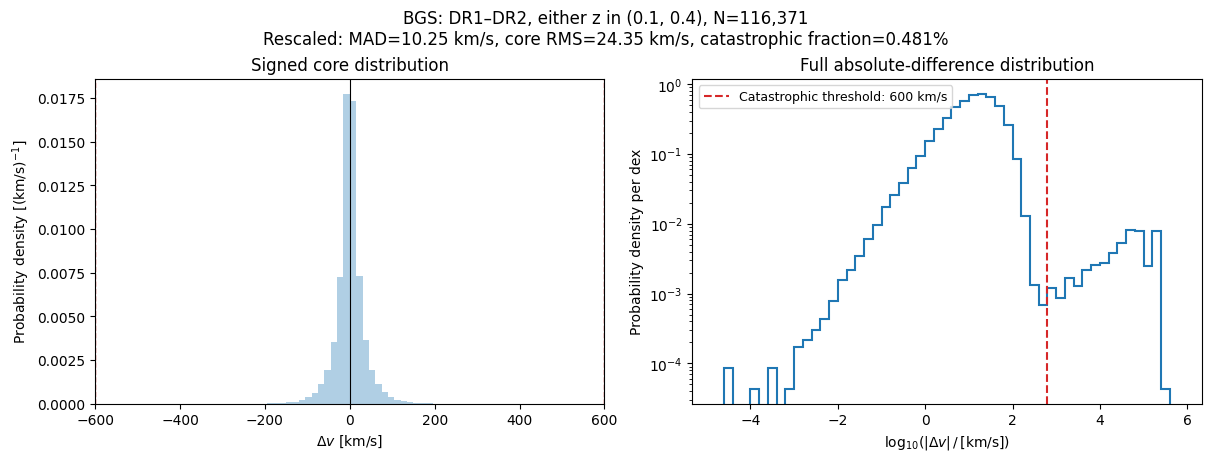

tracer,N_input,N_selected,N_core,N_catastrophic,N_zero,cthr,median_dv,mad,rms,fc_percent
,,,,,,km / s,km / s,km / s,km / s,
str3,int64,int64,int64,int64,int64,int64,float64,float64,float64,float64
BGS,148872,116371,115252,1119,0,600.000,-0.050,10.253,24.347,0.481


In [25]:
ERROR_ZRANGE = REDSHIFT_BIN_GLOBAL[TRACER]  # Set to None to use all paired redshifts.
fig, error_summary, dv_dr1_dr2, error_quantities = plot_repeat_error_distribution(
    pairs, TRACER, zcol=zcol, zrange=ERROR_ZRANGE)
plt.show()
error_summary

In [26]:
# Save newly built pairs; a saved catalog is reused without rewriting it.
if output.exists():
    print(f'Catalog already saved: {output}')
else:
    output.parent.mkdir(parents=True, exist_ok=True)
    pairs.write(output, overwrite=False)
    print(f'Saved {len(pairs):,} repeat pairs to {output}')


[000172.92]  09-15 05:28  astropy                      WARNING  VerifyWarning: Keyword name 'PERIOD_BY' is greater than 8 characters or contains characters not allowed by the FITS standard; a HIERARCH card will be created.


Saved 148,872 repeat pairs to /global/cfs/cdirs/desi/users/shengyu/repeats/DA2/loa-v1/BGSrepeats_vs_y1.fits


## Y1-only repeat sample

Both observations have `ZDATE < 20220900` and belong to different tiles with the
same `TARGETID`. Start from the selected parent observations, independently of
the DR1–DR2 pairs. A target needs at least two accepted Y1 observations; its later
DR2 observations do not affect membership in this sample.

Following the existing `get_repeats` convention, pair each target's first Y1
observation with each additional Y1 observation: N observations give N−1 pairs.
Here the first observation is ordered by `ZDATE`, then `LASTNIGHT`, then `TILEID`.
`EXACTLY_ONE` applies only to the cross-period sample above.

Reuse `y1/{TRACER}repeats_y1.fits` if it exists; otherwise save the newly built
Y1 pairs there. Both samples use loa-v1 redshifts and the same DV definition.

In [ ]:
if not loaded_saved_y1:
    pairs_y1 = pair_y1_observations(dr1, dr1_stop=DR1_STOP)
y1_stop = pairs_y1.meta.get('DR1_STOP', DR1_STOP)
assert np.all(pairs_y1['ZDATE_1'] < y1_stop)
assert np.all(pairs_y1['ZDATE_2'] < y1_stop)
assert np.all(pairs_y1['TILEID_1'] != pairs_y1['TILEID_2'])

if not loaded_saved_y1:
    zmean_y1 = 0.5 * (pairs_y1[f'{zcol}_1'] + pairs_y1[f'{zcol}_2'])
    pairs_y1['DV'] = CSPEED * (pairs_y1[f'{zcol}_1'] - pairs_y1[f'{zcol}_2']) / (1 + zmean_y1)
    pairs_y1.meta.update(TRACER=TRACER, VERSPEC=VERSPEC, DR1_STOP=DR1_STOP,
                         GOODZ=REQUIRE_GOODZ, PERIOD_BY='TILE_ZDATE',
                         PAIRMODE='first-vs-rest', SAMPLE='Y1-only',
                         DV_DEF='c*(z1-z2)/(1+(z1+z2)/2)')
print(f'{len(pairs_y1):,} Y1-only pairs from {len(np.unique(pairs_y1["TARGETID"])):,} targets')
pairs_y1[['TARGETID', 'TILEID_1', 'TILEID_2', 'ZDATE_1', 'ZDATE_2',
          'LASTNIGHT_1', 'LASTNIGHT_2', f'{zcol}_1', f'{zcol}_2', 'DV']][:20]

In [ ]:
if y1_output.exists():
    print(f'Y1 catalog already saved: {y1_output}')
else:
    y1_output_dir.mkdir(parents=True, exist_ok=True)
    pairs_y1.write(y1_output, overwrite=False)
    print(f'Saved {len(pairs_y1):,} Y1 repeat pairs to {y1_output}')

## Compare DR2, DR1–DR2, and DR1-only repeats

This section can run independently of the catalog-building cells above. It reads
all four tracers from the saved catalogs and compares **RMS, MAD, and catastrophic
fraction** using identical analysis cuts within each tracer.

| Sample | Catalog relative to `loa-v1/` | Pairing |
|:--|:--|:--|
| DR2 | `{tracer}repeats_info.fits` | First observation versus the rest across the full period |
| DR1 vs DR2 | `y1/{tracer}repeats_vs_y1.fits` | Exactly one accepted observation in each period (saved `EXACTONE=True`) |
| DR1 only | `y1/{tracer}repeats_y1.fits` | First Y1 observation versus the other Y1 observations |

DR2 includes DR1 observations. The DR2 catalog uses its saved pairing order; the Y1 catalog orders by tile date.
These are comparisons of the saved samples, not a partition into disjoint pairs
or a comparison of identical targets. Differences can reflect sample composition
and pairing rules as well as redshift precision. No extra LSS-membership cut is applied.

Use `Z_QF_1/2` for QSO and `Z_1/2` for the other tracers. Recompute
$\Delta v=c(z_1-z_2)/[1+(z_1+z_2)/2]$ for every sample. Require finite redshifts/DV,
a positive denominator, and **either** redshift strictly inside the tracer's
`REDSHIFT_BIN_GLOBAL` interval. Apply `get_cthr` and `get_dv_qu` identically:

- RMS = core RMS / $\sqrt{2}$, with $|\Delta v|<v_{\rm cut}$.
- MAD = $1.4828\,\mathrm{median}(|\Delta v|)/2$ (the repository's definition).
- $f_c$ = catastrophic pair percentage / 2, with $|\Delta v|\geq v_{\rm cut}$.

Counts remain pair counts. The table reports input/selected counts and excluded
nonfinite redshifts explicitly. The figure shows point estimates without uncertainty bars.

**QSO selection caveat:** the parent-writer notebook uses `Z_QF != 999999`,
which can retain nonfinite redshifts. These observations participate in the saved
pair construction (including the exactly-one-per-period counts), and pairs with
nonfinite redshifts are then excluded identically from all three metric samples.
Filtering invalid observations before pairing would define different samples.
The metrics here follow the saved catalogs; they do not rebuild that selection.

The common functions define the same quantities used in
`repeats_distribution.ipynb`, but that notebook also contains plots with
`use_lss=True` or a different choice of redshift for the bin/denominator.
Those selections need to match before comparing their numerical outputs.

**Validation:** all 12 saved catalogs passed the parent-membership, tile-date, pairing-completeness, and metric checks. See the [audit report](../results/three_repeat_samples_audit.md), including the QSO parent-selection caveat.


In [ ]:
# Standalone comparison setup: no parent catalog loading or pair rebuilding.
import sys
from pathlib import Path
import warnings
import fitsio
import numpy as np
from astropy.table import Table
from matplotlib import pyplot as plt
from IPython.display import display

for comparison_root in (Path.cwd(), *Path.cwd().parents):
    if (comparison_root / 'main' / 'dv_tools.py').is_file():
        break
else:
    raise FileNotFoundError('Run this section from within desi_y3_redshift_errors.')
sys.path.insert(0, str(comparison_root / 'main'))
from dv_tools import CSPEED, get_cthr, get_dv_qu
from helper import REDSHIFT_BIN_GLOBAL

COMPARISON_DIR = Path('/global/cfs/cdirs/desi/users/shengyu/repeats/DA2/loa-v1')
COMPARISON_TRACERS = ('BGS', 'LRG', 'ELG', 'QSO')
COMPARISON_SAMPLES = ('DR2', 'DR1 vs DR2', 'DR1 only')
COMPARISON_ZRANGES = {tracer: REDSHIFT_BIN_GLOBAL[tracer] for tracer in COMPARISON_TRACERS}
COMPARISON_RESULTS = comparison_root / 'main' / 'repeat_obs' / 'results'


def compare_saved_repeat_sample(path, tracer, sample, zrange):
    zcol = 'Z_QF' if tracer == 'QSO' else 'Z'
    zcols = [f'{zcol}_1', f'{zcol}_2']
    columns = ['TARGETID', *zcols, 'TILEID_1', 'TILEID_2']
    if sample != 'DR2':
        columns += ['ZDATE_1', 'ZDATE_2']
    data, header = fitsio.read(str(path), columns=columns, header=True)
    if np.any(data['TILEID_1'] == data['TILEID_2']):
        raise ValueError(f'Same-tile pairs found in {path}')
    if sample != 'DR2':
        cutoff = header['DR1_STOP']
        if cutoff != 20220900 or not np.all(data['ZDATE_1'] < cutoff):
            raise ValueError(f'Unexpected DR1 selection in {path}')
        if sample == 'DR1 vs DR2':
            if header['DR2_STOP'] != 20240410:
                raise ValueError(f'Unexpected DR2 cutoff in {path}')
            if not np.all((data['ZDATE_2'] > cutoff) & (data['ZDATE_2'] < header['DR2_STOP'])):
                raise ValueError(f'Unexpected DR2 selection in {path}')
            if not header['EXACTONE'] or len(np.unique(data['TARGETID'])) != len(data):
                raise ValueError(f'Expected exactly-one-per-period pairs in {path}')
        elif not np.all(data['ZDATE_2'] < cutoff) or header['PAIRMODE'] != 'first-vs-rest':
            raise ValueError(f'Unexpected Y1 selection or pairing in {path}')

    z1, z2 = (np.asarray(data[name], dtype=float) for name in zcols)
    zmin, zmax = zrange
    if not np.isfinite([zmin, zmax]).all() or zmin >= zmax:
        raise ValueError('Redshift limits must be finite and increasing.')
    finite_z = np.isfinite(z1) & np.isfinite(z2)
    denominator = 1 + (z1 + z2) / 2
    with np.errstate(divide='ignore', invalid='ignore', over='ignore'):
        dv_all = CSPEED * (z1 - z2) / denominator
    valid = finite_z & (denominator > 0) & np.isfinite(dv_all)
    in_range = ((zmin < z1) & (z1 < zmax)) | ((zmin < z2) & (z2 < zmax))
    selected = valid & in_range
    dv = dv_all[selected]
    cthr = get_cthr(tracer)
    if dv.size:
        with warnings.catch_warnings():
            warnings.filterwarnings('ignore', message='Mean of empty slice.', category=RuntimeWarning)
            qu = get_dv_qu(dv, cthr)
        qu['rms'] = qu['rms'] / np.sqrt(2)
        qu['mad'] = qu['mad'] / 2
        qu['fc'] = qu['fc'] / 2
    else:
        qu = dict(rms=np.nan, mad=np.nan, fc=np.nan)
    return dict(tracer=tracer, sample=sample, zmin=zmin, zmax=zmax,
                N_input=len(data), N_nonfinite_z=int(np.count_nonzero(~finite_z)),
                N_invalid_dv=int(np.count_nonzero(finite_z & ~valid)),
                N_outside_z=int(np.count_nonzero(valid & ~in_range)),
                N_selected=len(dv), N_targets=len(np.unique(data['TARGETID'][selected])),
                N_core=int(np.count_nonzero(np.abs(dv) < cthr)),
                N_catastrophic=int(np.count_nonzero(np.abs(dv) >= cthr)),
                cthr=cthr, rms=qu['rms'], mad=qu['mad'], fc_percent=qu['fc'],
                catalog=str(path))


In [ ]:
comparison_rows = []
for comparison_tracer in COMPARISON_TRACERS:
    comparison_paths = (
        COMPARISON_DIR / f'{comparison_tracer}repeats_info.fits',
        COMPARISON_DIR / 'y1' / f'{comparison_tracer}repeats_vs_y1.fits',
        COMPARISON_DIR / 'y1' / f'{comparison_tracer}repeats_y1.fits',
    )
    for comparison_sample, comparison_path in zip(COMPARISON_SAMPLES, comparison_paths):
        comparison_rows.append(compare_saved_repeat_sample(
            comparison_path, comparison_tracer, comparison_sample,
            COMPARISON_ZRANGES[comparison_tracer]))
comparison_summary = Table(rows=comparison_rows)
for comparison_name in ('cthr', 'rms', 'mad'):
    comparison_summary[comparison_name].unit = 'km/s'
    comparison_summary[comparison_name].format = '.3f'
comparison_summary['fc_percent'].unit = '%'
comparison_summary['fc_percent'].format = '.4f'

# Keep a machine-readable table with counts, cuts, units, and source paths.
COMPARISON_RESULTS.mkdir(parents=True, exist_ok=True)
comparison_summary.meta.update(
    dv_definition='c*(z1-z2)/(1+(z1+z2)/2)', redshift_selection='either, strict bounds',
    rms_scale='1/sqrt(2)', mad_scale='1/2', fc_scale='1/2', use_lss=False)
comparison_summary.write(COMPARISON_RESULTS / 'three_repeat_samples_metrics.ecsv', overwrite=True)
comparison_summary.write(COMPARISON_RESULTS / 'three_repeat_samples_metrics.csv', overwrite=True)
display(comparison_summary[['tracer', 'sample', 'zmin', 'zmax', 'N_input',
                            'N_nonfinite_z', 'N_selected', 'rms', 'mad', 'fc_percent']])


tracer,sample,zmin,zmax,N_input,N_nonfinite_z,N_selected,rms,mad,fc_percent
,,,,,,,km / s,km / s,%
str3,str16,float64,float64,int64,int64,int64,float64,float64,float64
BGS,DR2,0.1,0.4,465089,0,363856,24.029,9.911,0.3797
BGS,DR1 vs DR2,0.1,0.4,148872,0,116371,24.347,10.253,0.4808
BGS,DR1 only,0.1,0.4,101414,0,79481,23.859,9.964,0.4120
LRG,DR2,0.4,1.1,233471,0,208024,61.017,30.234,0.2937
LRG,DR1 vs DR2,0.4,1.1,85354,0,76049,60.165,30.413,0.3136
LRG,DR1 only,0.4,1.1,54556,0,48519,61.430,30.436,0.3019
ELG,DR2,0.8,1.6,549657,0,481364,19.788,6.368,0.1380
ELG,DR1 vs DR2,0.8,1.6,154432,0,134423,20.238,6.404,0.1439


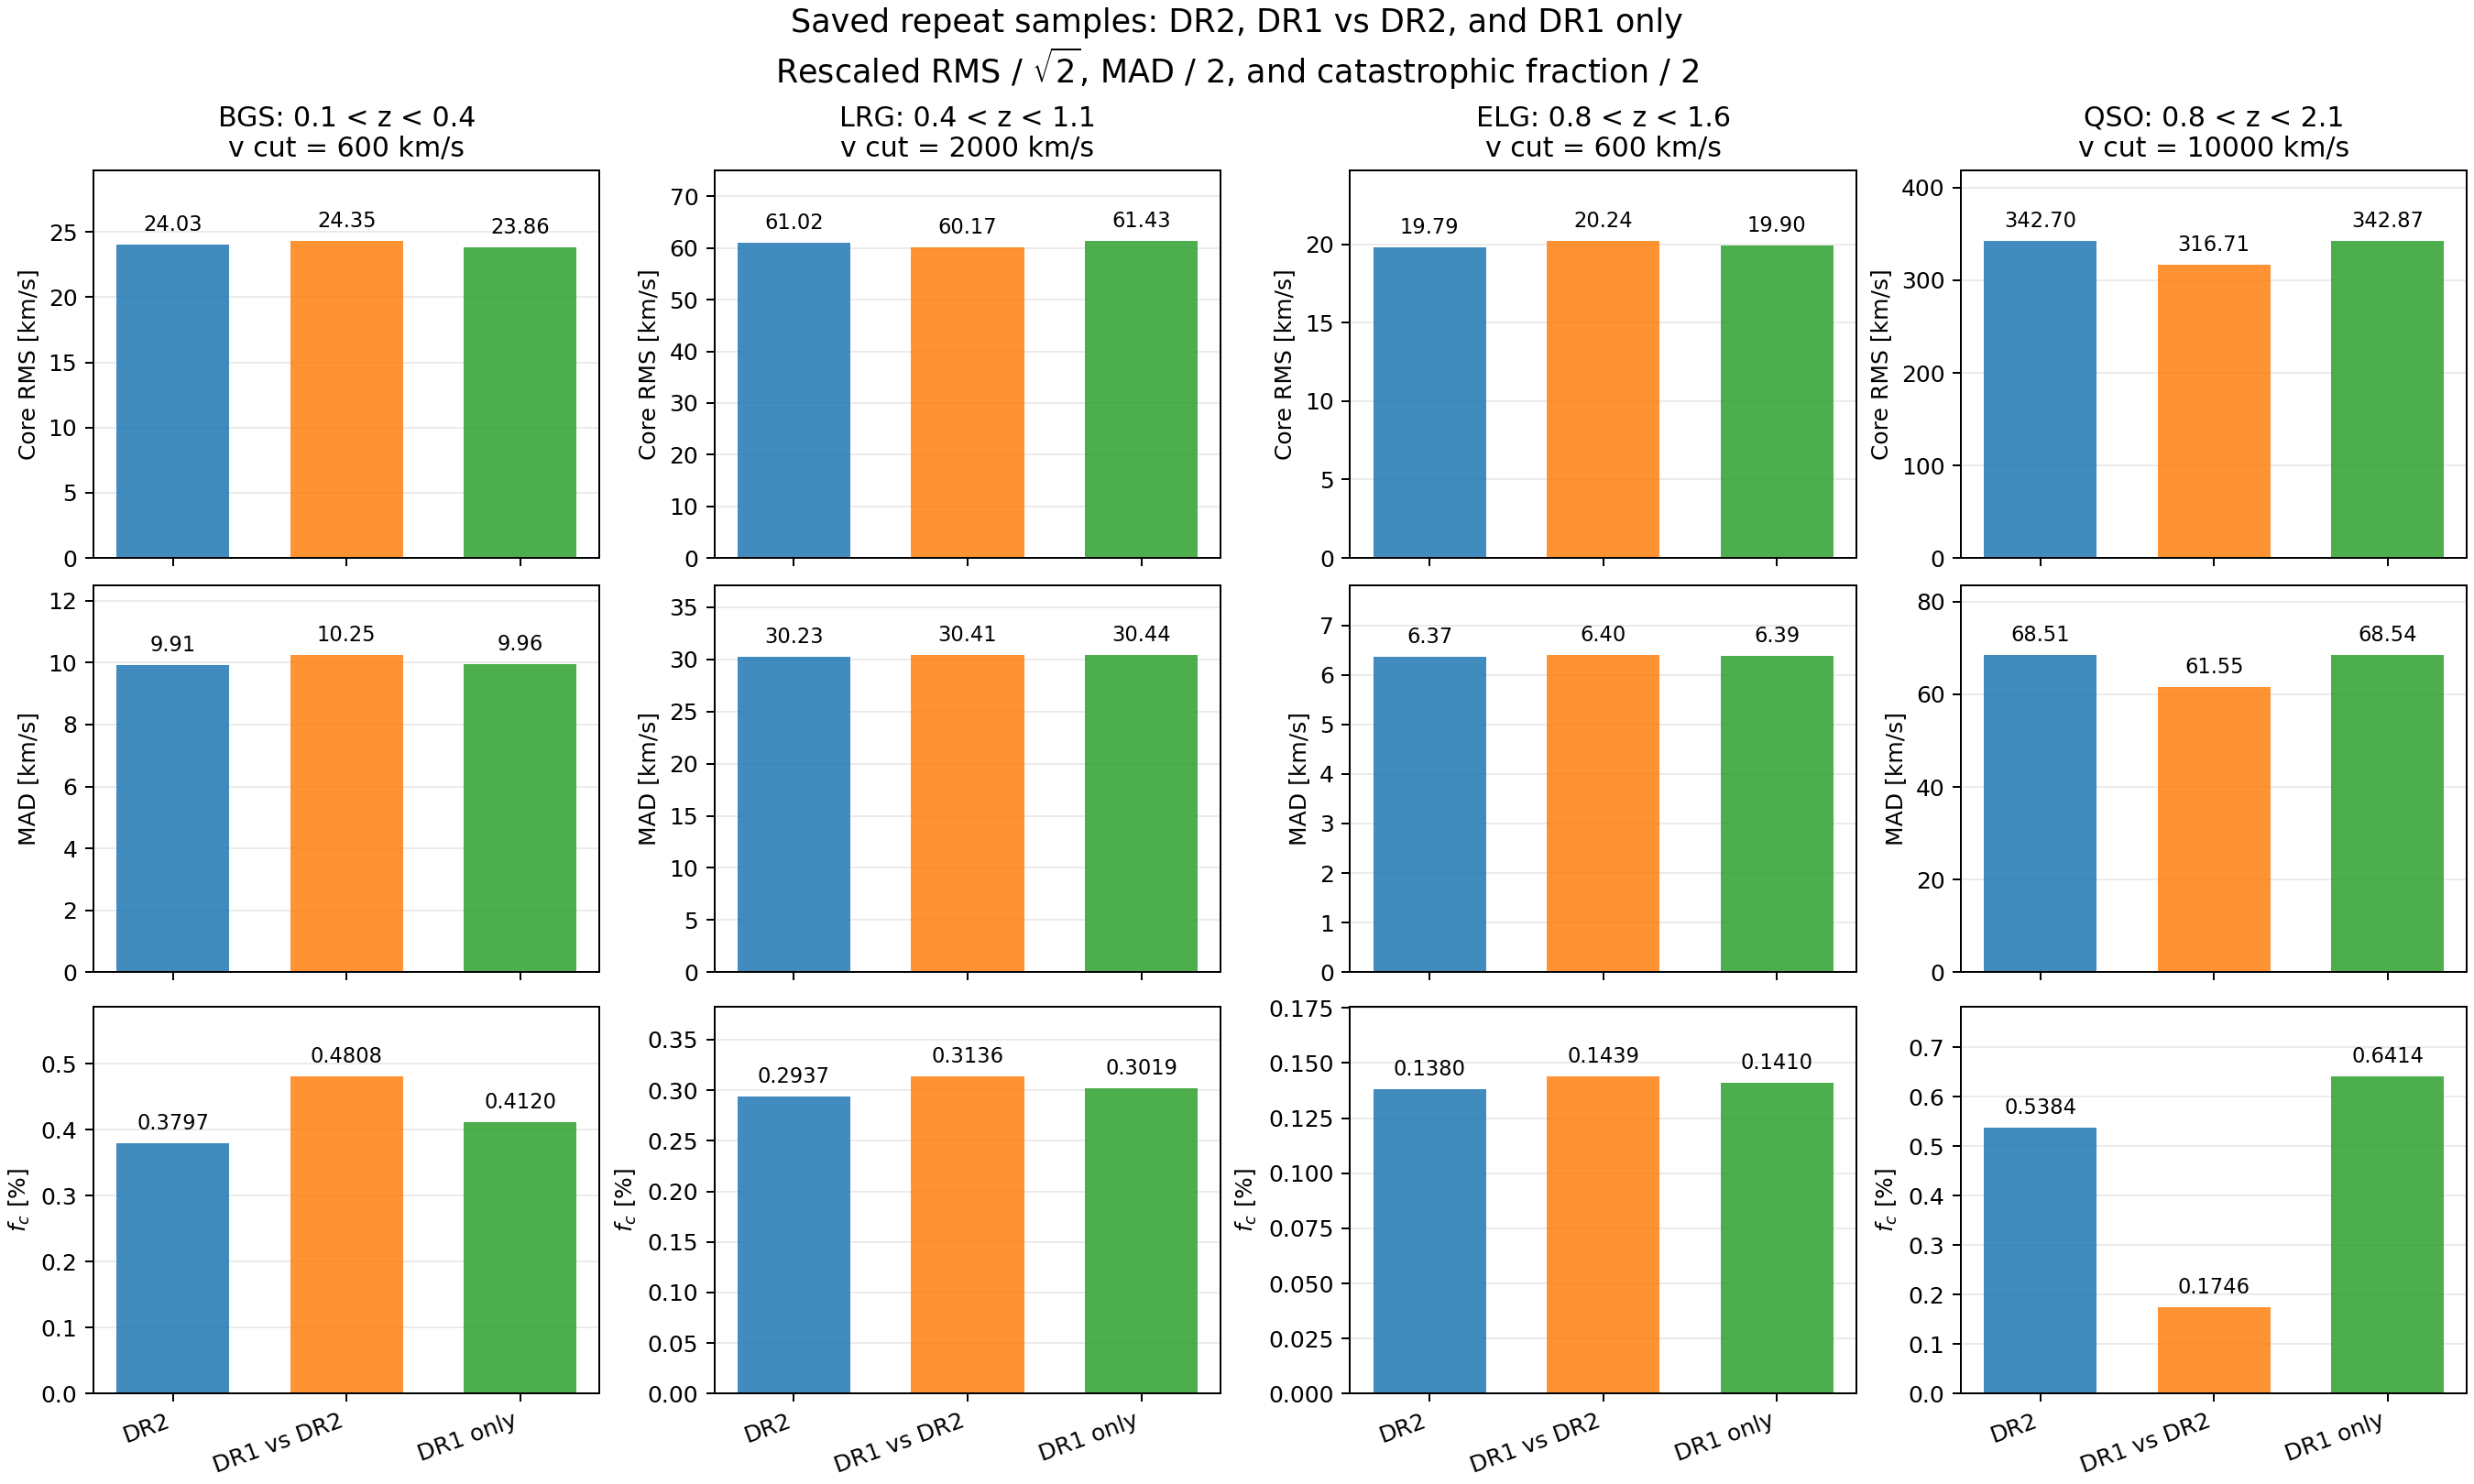

Saved comparison table and figure in /global/u1/s/shengyu/Y3/desi_y3_redshift_errors/main/repeat_obs/results


In [ ]:
comparison_fig, comparison_axes = plt.subplots(
    3, len(COMPARISON_TRACERS), figsize=(15, 9), sharex=True, constrained_layout=True,
    squeeze=False)
comparison_colors = ['C0', 'C1', 'C2']
for comparison_col, comparison_tracer in enumerate(COMPARISON_TRACERS):
    comparison_subset = comparison_summary[comparison_summary['tracer'] == comparison_tracer]
    for comparison_row, (metric, ylabel) in enumerate([
            ('rms', 'Core RMS [km/s]'), ('mad', 'MAD [km/s]'), ('fc_percent', r'$f_c$ [%]')]):
        ax = comparison_axes[comparison_row, comparison_col]
        values = np.asarray(comparison_subset[metric], dtype=float)
        ax.bar(np.arange(3), values, color=comparison_colors, width=0.65, alpha=0.85)
        for index, value in enumerate(values):
            if np.isfinite(value):
                ax.annotate(f'{value:.4f}' if metric == 'fc_percent' else f'{value:.2f}',
                            (index, value), xytext=(0, 4), textcoords='offset points',
                            ha='center', va='bottom', fontsize=9)
            else:
                ax.text(index, 0.05, 'undefined', transform=ax.get_xaxis_transform(), ha='center')
        finite_values = values[np.isfinite(values)]
        ymax = float(finite_values.max()) if finite_values.size else 0.0
        ax.set_ylim(0, 1.22 * ymax if ymax > 0 else 1.0)
        ax.set_ylabel(ylabel)
        ax.set_xticks(np.arange(3))
        ax.set_xticklabels(['DR2', 'DR1 vs DR2', 'DR1 only'], rotation=20, ha='right')
        ax.grid(axis='y', alpha=0.25)
        ax.set_axisbelow(True)
    zmin, zmax = COMPARISON_ZRANGES[comparison_tracer]
    comparison_axes[0, comparison_col].set_title(
        f'{comparison_tracer}: {zmin:g} < z < {zmax:g}\n'
        f'v cut = {get_cthr(comparison_tracer):g} km/s')
comparison_fig.suptitle(
    'Saved repeat samples: DR2, DR1 vs DR2, and DR1 only\n'
    r'Rescaled RMS / $\sqrt{2}$, MAD / 2, and catastrophic fraction / 2', fontsize=14)
for extension in ('png', 'pdf'):
    comparison_fig.savefig(COMPARISON_RESULTS / f'three_repeat_samples_metrics.{extension}', dpi=180)
plt.show()
print(f'Saved comparison table and figure in {COMPARISON_RESULTS}')
